In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [113]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [114]:
df.shape

(32581, 12)

In [115]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


In [116]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [117]:
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

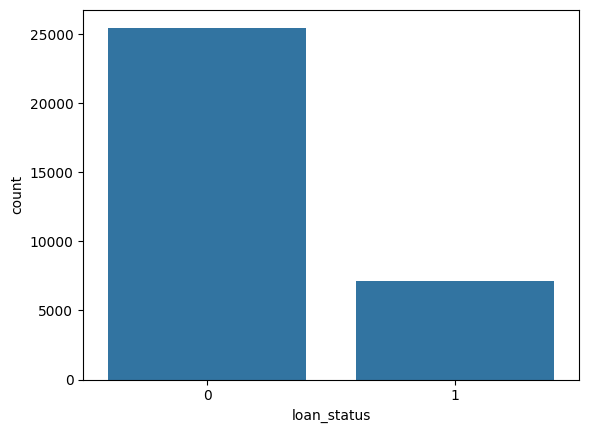

In [118]:
sns.countplot(x='loan_status',data=df)

outlier


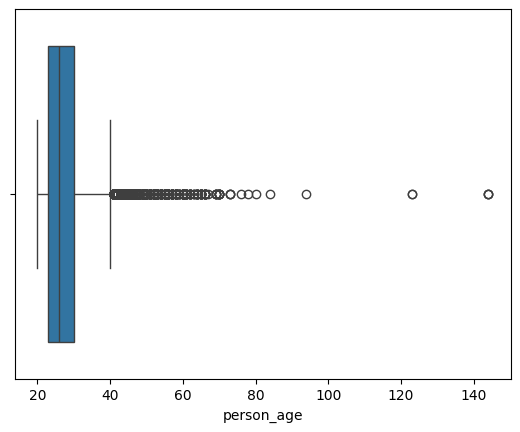

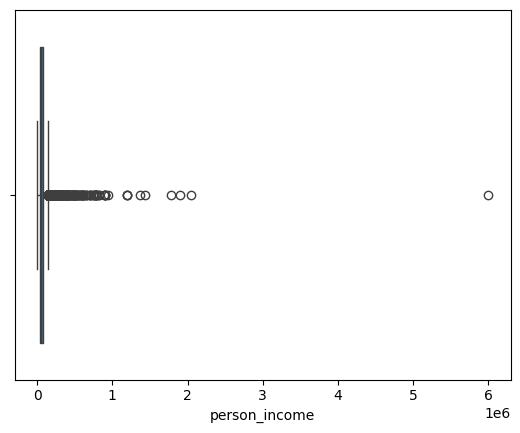

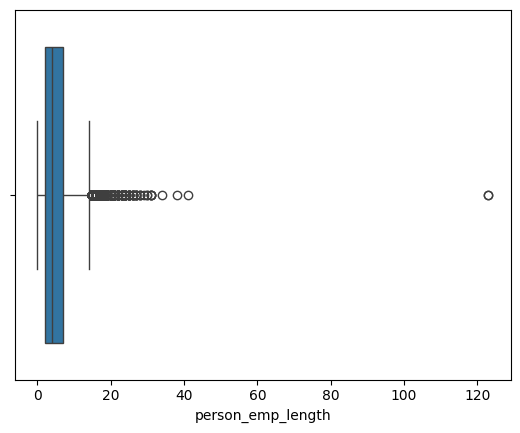

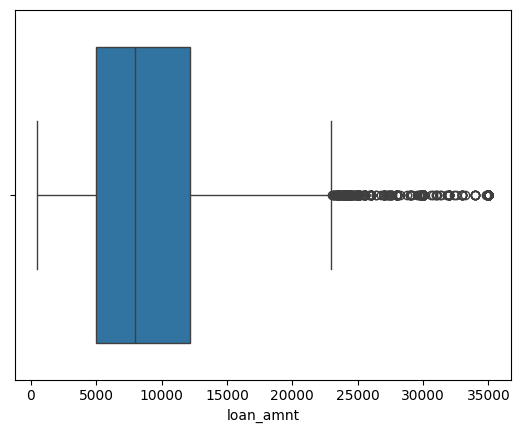

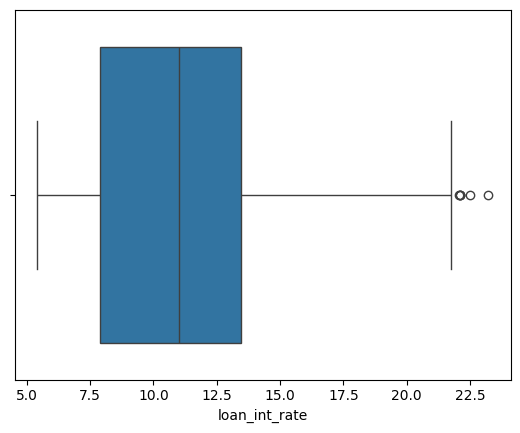

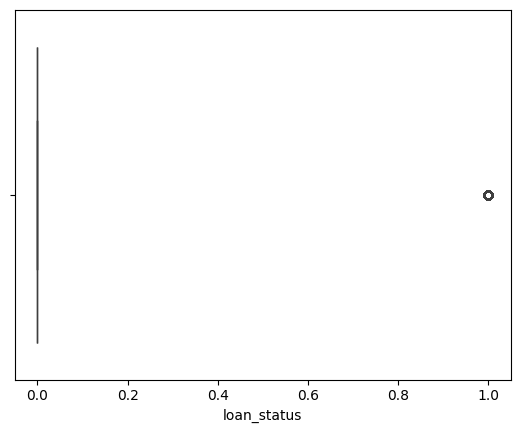

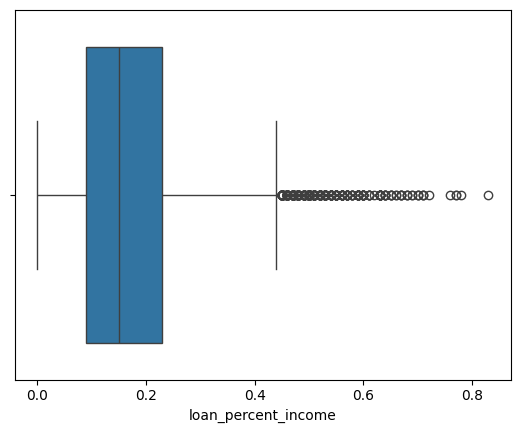

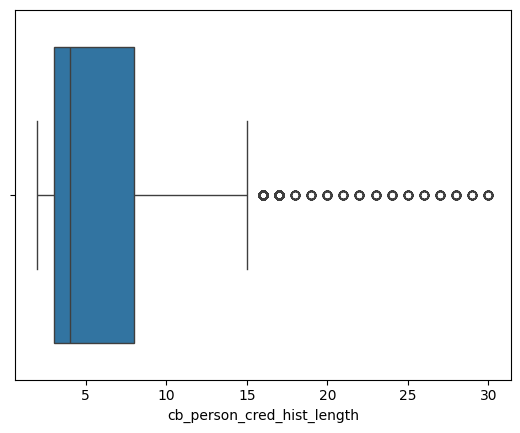

In [119]:
numerical_col = df.select_dtypes(include=np.number)

for i in numerical_col:
  sns.boxplot(x=df[i])
  plt.show()


In [120]:
(df['person_age'] > 100).sum()

np.int64(5)

In [121]:
(df['person_emp_length'] > 60).sum()

np.int64(2)

In [122]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


# Correlation check

<Axes: >

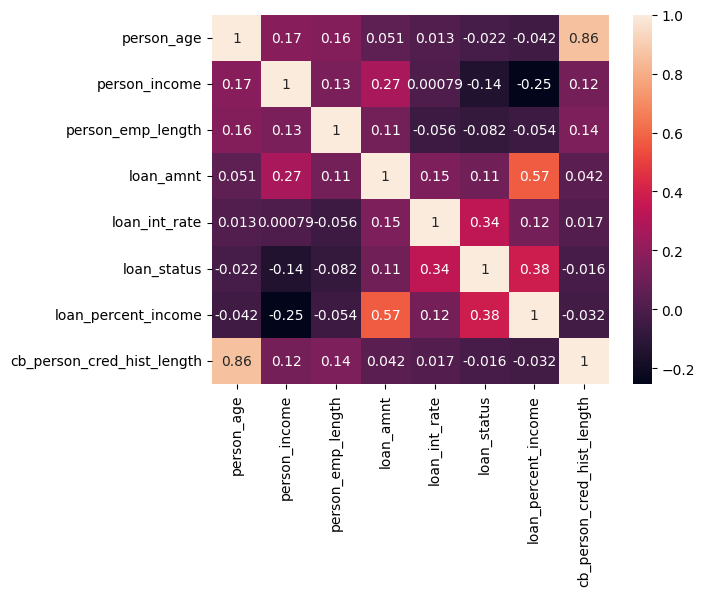

In [123]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

#Data valition and Outlier handing
remove duplicate row


In [124]:
df_copy = df.copy()

print(f"Original rows: {df_copy.shape[0]}")
#remove duplicate rows

df_copy.drop_duplicates(inplace=True)
print(f"Rows after removing duplicates: {df_copy.shape[0]}")

Original rows: 32581
Rows after removing duplicates: 32416


In [125]:
# remove ages below 18 or above 100
df_copy = df_copy[df_copy['person_age'] >= 18]
df_copy = df_copy[df_copy['person_age'] <= 100]

# remove employement length greater than age or extereme outlier(>60)
df_copy = df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length'] <= 60]


In [126]:
# remove the rows with zero or -ve loan amount
df_copy = df_copy[df_copy['loan_amnt'] > 0]

In [127]:
print("loan interest rate range from (min: 5.42 and max: 23.22)")

loan interest rate range from (min: 5.42 and max: 23.22)


#Features,target and train test split

In [128]:
X = df_copy.drop('loan_status',axis=1)
y = df_copy['loan_status']

In [129]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42,stratify=y) #stratify = mainatain balance of 1 and 0 for traing and testing

In [130]:
numeric_col = df_copy.select_dtypes(include=['int64','float64']).columns.tolist()
if 'loan_status' in numeric_col:
    numeric_col.remove('loan_status')

categorical_col = df_copy.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

#handle class imbalance

In [131]:
neg,pos = np.bincount(y_train)

In [132]:
scale_weights = neg/pos

#pipelines and column transformation

In [133]:
#logistic regression: impute + SCALE Numeric, impute + One Hot Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder



In [134]:
preprocessor_lr = ColumnTransformer(
    transformers=[
        ('num', Pipeline(
            [
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]
        ), numeric_col),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_col)
    ]
)

preprocessing for XGBoost

In [135]:
preprocessor_xg = ColumnTransformer(
    transformers=[
        ('num', Pipeline(
            [
                ('imputer', SimpleImputer(strategy='median')),
            ]
        ), numeric_col),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_col)
    ]
)

#Evaluataion Helper function
-it shows accuracy,precision,recall,F1 score and more.
Also shows confusion matrix and a presion recall curve

In [136]:

from sklearn.metrics import precision_recall_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_model(model_name, model, X_test, y_test,threshold=None):
    y_pred = model.predict(X_test)
    y_pred_prob = model.predict_proba(X_test)[:, 1]

    if threshold:
      best_threshold = threshold
      y_pred = (y_pred_prob >= threshold).astype(int)
    else:
      best_threshold = 0.5
      y_pred = model.predict(X_test)



    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print(f"Accuracy: {accuracy:.2f}")
    print(f"Best threshold: {best_threshold}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1 Score: {f1:.2f}")

    # Confusion matrix and classification report
    cm = confusion_matrix(y_test, y_pred)
    print(f"\n{model_name} Classification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()

    # Precision-Recall curve
    precisions, recalls, thresholds = precision_recall_curve(
        y_test, y_pred_prob
    )

    plt.figure(figsize=(6, 4))
    plt.plot(recalls, precisions)
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.show()


# Stratified cross validation


*   one single train test split may not be reliable.
*   we split the traing data into five folds instead.



In [137]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc','accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1'}

# Logistic regression

In [138]:
from sklearn.linear_model import LogisticRegression
lr_cr_model = Pipeline([
    ('preprocessor',preprocessor_lr),
    ("classifier",LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42))
])
lr_cr_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

#XGBoost

In [139]:
# from xgboost import XGBClassifier
# xgb_cv_pipeline = Pipeline([
#     ('preprocessor',preprocessor_xg),
#     ('classifier',XGBClassifier(
#         n_estimator = 300,max_depth=5,learning_rate=0.1,
#         scale_pos_weight=scale_weights,random_state=42,
#     ))
# ])
# xgb_cv_pipeline.

In [140]:
from xgboost import XGBClassifier
xg_model = Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(learning_rate=0.1,
                                scale_pos_weight=scale_weights,random_state=42))
])
xg_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [141]:
#Evaluate the logostic model

In [142]:
# Run and display cross validation results
for cv_name, pipe in [('Logistic regression', lr_cr_model), ('XGBoost', xg_model)]:
    print(f"\nRunning CV for: {cv_name}...")
    cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    print(f"ROC-AUC: {cv_results['test_roc_auc'].mean()}")
    print(f"Accuracy: {cv_results['test_accuracy'].mean()}")
    print(f"Recall: {cv_results['test_recall'].mean()}")
    print(f"F1: {cv_results['test_f1'].mean()}")


Running CV for: Logistic regression...
ROC-AUC: 0.8713404164641778
Accuracy: 0.8110233618747266
Recall: 0.7792147057128033
F1: 0.6404194397951647

Running CV for: XGBoost...
ROC-AUC: 0.9426013072233255
Accuracy: 0.9154315472987034
Recall: 0.7844773832170787
F1: 0.8003069219302692


In [143]:
cv_results

{'fit_time': array([0.55417228, 0.56471014, 0.54111958, 0.52284622, 0.32630873]),
 'score_time': array([0.09947205, 0.10105181, 0.13867855, 0.10375547, 0.05763745]),
 'test_roc_auc': array([0.94767664, 0.94189689, 0.94159926, 0.93706365, 0.94477009]),
 'test_accuracy': array([0.91051136, 0.9202178 , 0.91761364, 0.91453598, 0.91427895]),
 'test_precision': array([0.79148472, 0.83084005, 0.82867133, 0.8143508 , 0.81976744]),
 'test_recall': array([0.79495614, 0.79166667, 0.77960526, 0.78313253, 0.77302632]),
 'test_f1': array([0.79321663, 0.81078046, 0.80338983, 0.79843663, 0.79571106])}

#Baseline Model - Logistic regression

*   Start with simple model


In [144]:
# baseline_model = Pipeline([
#     ('Preprocessor',preprocessor_lr),
#     ('classifier',LogisticRegression(class_weight="balanced"))
# ])

# baseline_model.fit(X_train,y_train)

Accuracy: 0.82
Best threshold: 0.5
Precision: 0.55
Recall: 0.78
F1 Score: 0.65

Logistic regerssion model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      8157
           1       0.55      0.78      0.65      2246

    accuracy                           0.82     10403
   macro avg       0.74      0.80      0.76     10403
weighted avg       0.85      0.82      0.83     10403



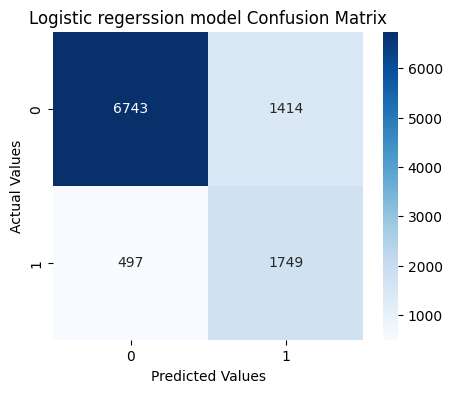

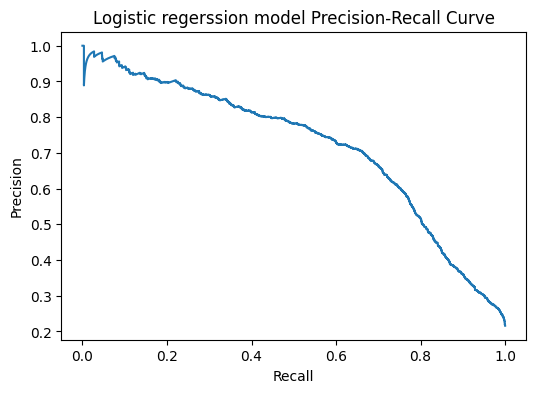

In [145]:
evaluate_model("Logistic regerssion model",lr_cr_model,X_test,y_test)

Accuracy: 0.92
Best threshold: 0.5
Precision: 0.83
Recall: 0.79
F1 Score: 0.81

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      8157
           1       0.83      0.79      0.81      2246

    accuracy                           0.92     10403
   macro avg       0.88      0.87      0.88     10403
weighted avg       0.92      0.92      0.92     10403



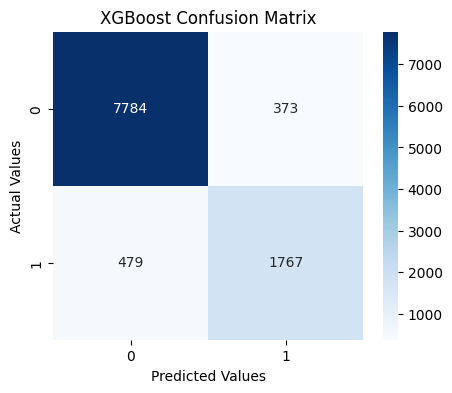

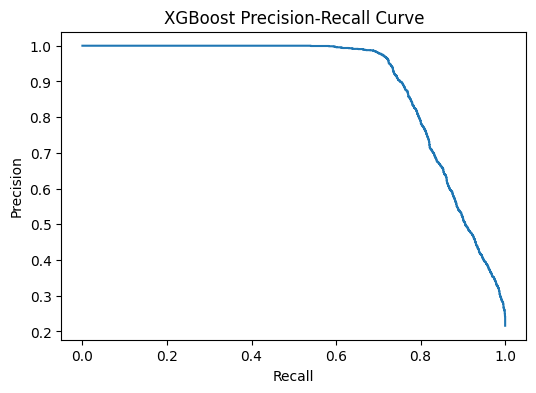

In [146]:
evaluate_model("XGBoost",xg_model,X_test,y_test)

#Hyperparameter tuning

In [147]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# Correcting parameter distributions for RandomizedSearchCV
param_dist = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth": randint(3, 9),
    "classifier__learning_rate": uniform(0.01, 0.49),          # range [0.01, 0.50]
    "classifier__subsample": uniform(0.5, 0.5),                # range [0.5, 1.0]
    "classifier__colsample_bytree": uniform(0.5, 0.5),         # range [0.5, 1.0]
    "classifier__gamma": randint(0, 5)
}

In [148]:
# Initialize RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=xg_model,
    param_distributions=param_dist,
    n_iter=50, # randomly selects 50 hyperparameter combinations.
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7d754cc7b6f0>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7d754cc7ac40>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7d754cc79220>},
                   random_state=42, scoring='average_precision', verbose=1)

In [149]:
print(f"Score after performing Tunning {random_search.best_score_}")

Score after performing Tunning 0.902707056048358


In [150]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.6467440873590191),
 'classifier__gamma': 2,
 'classifier__learning_rate': np.float64(0.10743277800351451),
 'classifier__max_depth': 5,
 'classifier__n_estimators': 568,
 'classifier__subsample': np.float64(0.8856351733429728)}

Accuracy: 0.92
Best threshold: 0.5
Precision: 0.83
Recall: 0.80
F1 Score: 0.81

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      8157
           1       0.83      0.80      0.81      2246

    accuracy                           0.92     10403
   macro avg       0.89      0.88      0.88     10403
weighted avg       0.92      0.92      0.92     10403



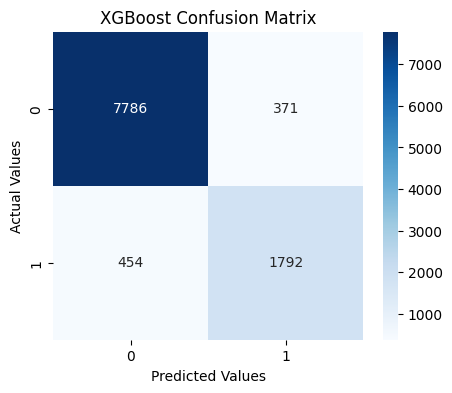

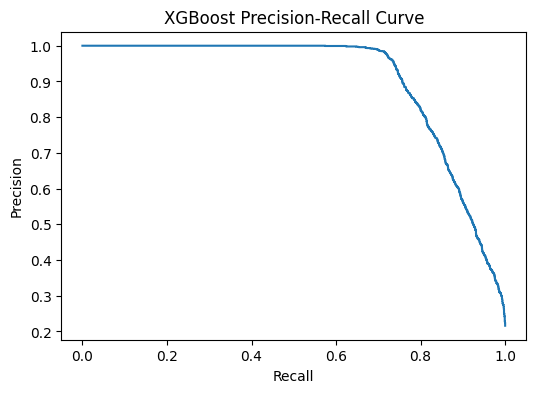

In [151]:
# after hyperparameter tuning
evaluate_model("XGBoost",random_search,X_test,y_test)

#Classification threshold

Accuracy: 0.78
Best threshold: 0.9997060894966125
Precision: 1.00
Recall: 0.00
F1 Score: 0.00

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      8157
           1       1.00      0.00      0.00      2246

    accuracy                           0.78     10403
   macro avg       0.89      0.50      0.44     10403
weighted avg       0.83      0.78      0.69     10403



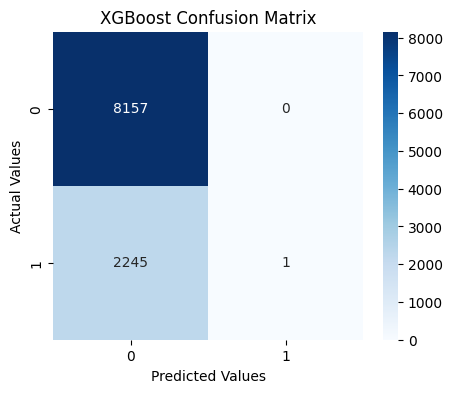

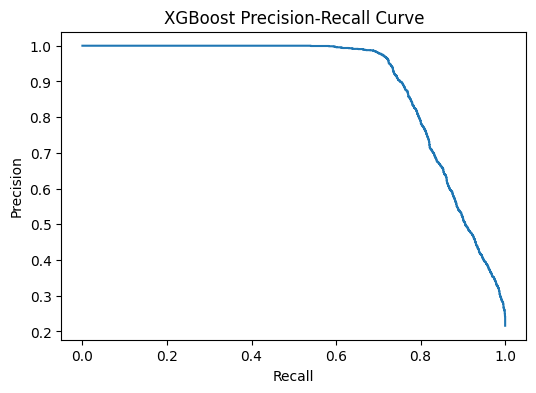

In [152]:
#Get the prob. of class 1 from XGBoost
prob = xg_model.predict_proba(X_test)[:,1]

#For each threshold calculate precision and recall
precisions,recalls,thresholds = precision_recall_curve(y_test,prob)

#Calculate f1 score for each threshold
f1 = 2*(precisions-recalls)/(precisions + 1e-9)

# get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

#evaluate the
evaluate_model("XGBoost",xg_model,X_test,y_test,best_threshold)


# Probability Calibration


*   Sometimes a model's doesn't mean what it says



#Methods by which we can fix the poorly calibrated model.

1.   Platt Scaling/ Sigmoid -> Adjust the probabilties using a sigmoid curve
2.   Isotonic Regression -> Learn a flexible mapping from old prob.
3. Temperature scaling -> Adjust the confidence of neural network prediction




In [153]:
#1. Calibrated XGBoost model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    cv='prefit',
    method='sigmoid'
)
calibrated_model.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


CalibratedClassifierCV(cv='prefit',
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    Simple...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.10743277800351451),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=5,
                                                                max_leaves=None,
                                                                min_child_weight=None,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=568,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [154]:

from sklearn.metrics import precision_recall_curve
import numpy as np

# Get probabilities from the CALIBRATED model
calibrated_proba = calibrated_model.predict_proba(X_test)[:, 1]

# Find the threshold with the highest F1 score
precisions, recalls, thresholds = precision_recall_curve(
    y_test, calibrated_proba
)

f1_scores = (
    2 * (precisions * recalls) /
    (precisions + recalls + 1e-9)
)

best_threshold = thresholds[np.argmax(f1_scores[:-1])]

print("New threshold:", best_threshold)


New threshold: 0.8864553813653885


In [155]:
#2. Get probabilites
uncalibrated = xg_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

In [156]:
uncalibrated

array([0.1177174 , 0.09880313, 0.41406897, ..., 0.06129934, 0.23803125,
       0.97992206], dtype=float32)

In [157]:
calibrated

array([0.00225628, 0.00217662, 0.03297815, ..., 0.00185813, 0.03869874,
       0.9946274 ])

In [158]:
#3. Create calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test,uncalibrated,n_bins=10)

In [159]:
actual_cal, predicted_cal = calibration_curve(y_test,calibrated,n_bins=10)

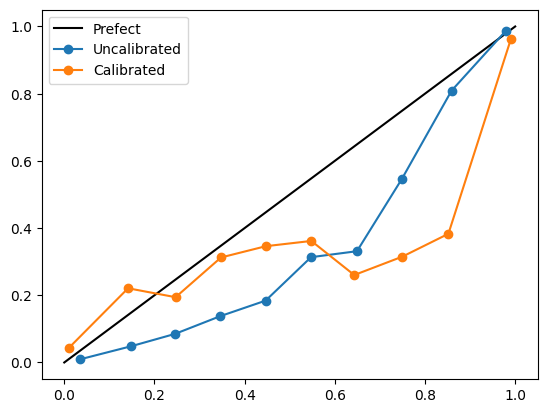

In [160]:
#4. Plot
plt.plot([0,1],[0,1],'k-',label="Prefect")
plt.plot(
    predicted_uncal,
    actual_uncal,
    marker='o',
    label='Uncalibrated'
)
plt.plot(
    predicted_cal,
    actual_cal,
    marker='o',
    label='Calibrated'
)
plt.legend()

#SHAP integration - Global & local

*   SHAP helps us understanding why the model makes a decision.
*   It is way of explaining a "black box" model



In [161]:
!pip install shap

In [162]:
import shap

# get the trainded XGBoost classifier model out of the pipeline
xgb_classifier = xg_model.named_steps['classifier']

# transform X_test using the same preprocssing used for training
X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)

# get feauture anmes after one hot encoding
feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()

In [163]:
# convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed,columns=feature_names)
X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,27.0,69000.0,1.0,2000.0,6.99,0.03,5.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,34.0,82000.0,3.0,5000.0,8.32,0.06,9.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,24.0,30000.0,0.0,4600.0,10.99,0.15,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,35.0,95000.0,17.0,15000.0,11.49,0.16,10.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,21.0,31000.0,5.0,6000.0,7.51,0.19,4.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10398,22.0,91234.0,6.0,12000.0,11.83,0.13,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
10399,25.0,55000.0,3.0,5000.0,10.99,0.09,4.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
10400,22.0,90000.0,3.0,12000.0,8.94,0.13,3.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
10401,23.0,30000.0,6.0,10000.0,7.66,0.33,3.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [164]:
# create SHAP explainer built for tree based model
explainer = shap.TreeExplainer(xgb_classifier)

In [165]:
# calculate SHAP values for every row in the test set

shap_values = explainer.shap_values(X_test_df)
shap_values

array([[ 0.04399857,  0.04263779,  0.09801882, ..., -0.00785964,
        -0.00805606,  0.        ],
       [-0.20236444, -1.0845456 , -0.15912656, ..., -0.00853321,
        -0.00331043,  0.        ],
       [-0.02769572,  0.7397295 ,  0.03290172, ..., -0.00770894,
         0.02737925,  0.        ],
       ...,
       [ 0.10679983, -1.1099346 , -0.11794779, ..., -0.00907352,
        -0.00309707,  0.        ],
       [ 0.02065774,  0.45021787, -0.21737243, ..., -0.00679155,
        -0.00529028,  0.        ],
       [-0.01330218, -0.6000857 , -0.11346805, ..., -0.00781418,
         0.00179192,  0.        ]], dtype=float32)

# global explanation

this shows which feature matter most overall.

It also shows a feature increase or decrease risk

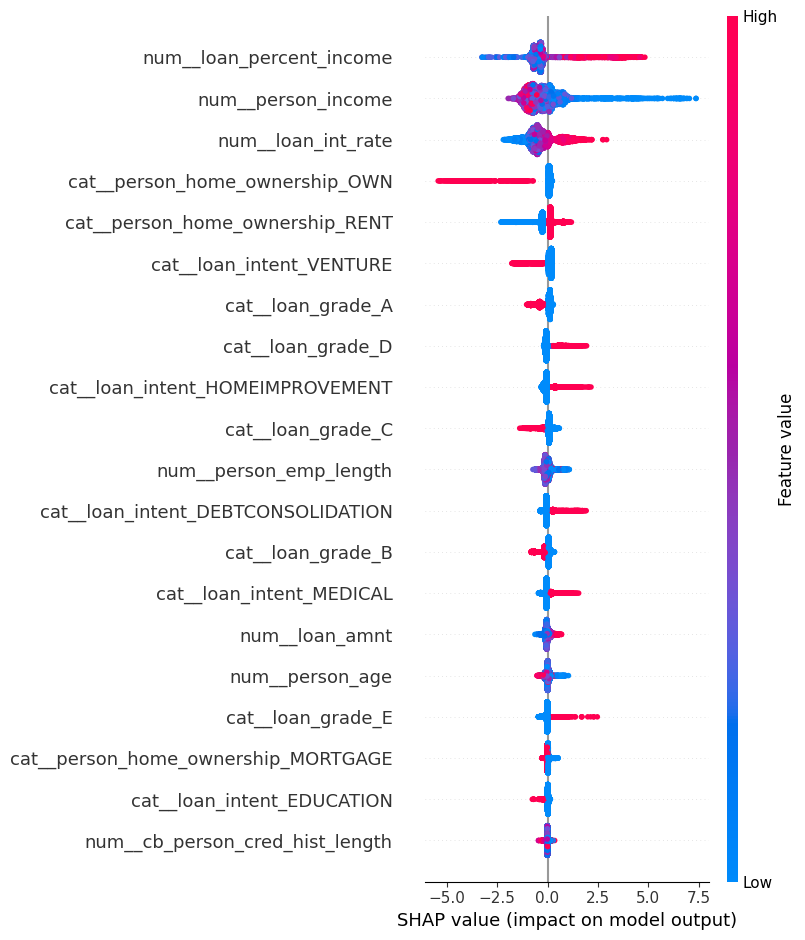

In [166]:
shap.summary_plot(shap_values,X_test_df)

#Local explanation

This shows why one specific application got their score.

It breaks the score down feature by feature

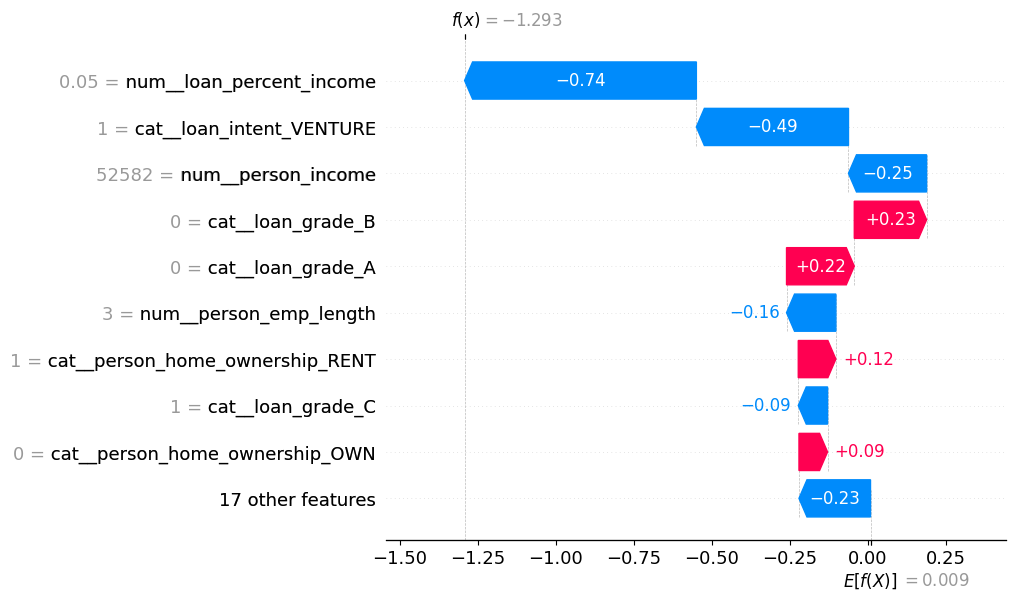

In [167]:
#Pick one row to explain, e.g the 5th applicant in the test set

row_index = 5

#Draw a waterfall plot showing how each feature pushed the predction up or down
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[row_index],
        base_values=explainer.expected_value,
        data=X_test_df.iloc[row_index],
        feature_names=X_test_df.columns
    )
)

#Analyzing false positive and false negatives

In [168]:
#Get prediction from best performing XGBoost model on the test set
y_pred = random_search.predict(X_test)

In [169]:
#Create a datafram to easily compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [170]:
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
19041,27,69000,RENT,1.0,MEDICAL,A,2000,6.99,0.03,N,5,0,0
21177,34,82000,RENT,3.0,HOMEIMPROVEMENT,A,5000,8.32,0.06,N,9,0,0
4294,24,30000,RENT,0.0,MEDICAL,C,4600,NaN,0.15,Y,2,0,0
26042,35,95000,MORTGAGE,17.0,HOMEIMPROVEMENT,B,15000,11.49,0.16,N,10,0,0
2228,21,31000,MORTGAGE,5.0,PERSONAL,A,6000,7.51,0.19,N,4,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
16891,22,91234,MORTGAGE,6.0,MEDICAL,B,12000,11.83,0.13,N,2,0,0
5428,25,55000,RENT,3.0,DEBTCONSOLIDATION,C,5000,NaN,0.09,Y,4,0,0
13080,22,90000,RENT,3.0,DEBTCONSOLIDATION,A,12000,8.94,0.13,N,3,0,0
1990,23,30000,MORTGAGE,6.0,EDUCATION,A,10000,7.66,0.33,N,3,0,0


In [171]:
#Idetify False +ve :  Model predicted 1 but the actual was 0
false_positives = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]

#Identify False -ve : Model predicted 0 butu the actual was 1
false_negatives = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]


In [172]:
print(f"False positives: {len(false_positives)}")
print(f"False negatives: {len(false_negatives)}")

False positives: 371
False negatives: 454


# save the final model

In [173]:
import joblib

joblib.dump(calibrated_model,"credit_risk_model.pkl")

['credit_risk_model.pkl']

In [174]:
joblib.dump(best_threshold,"best_threshold.pkl")

['best_threshold.pkl']